# Check fire overlap across years

In [143]:
import os
import tqdm
import numpy as np
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

from geopandas.tools import sjoin
from tqdm.contrib import itertools

In [212]:
# States that I don't want from the US
not_continental = ['Puerto Rico', 'Alaska', 'Hawaii']

# Read in NaturalEarth data and filter to US states 
world = gpd.read_file('data/ne_10m_admin_1_states_provinces.zip')
us = (
    world[(world.iso_a2 == 'US') & (~world.name.isin(not_continental))]
    .filter(['name', 'code_local', 'geometry'])
    .to_crs('EPSG:5070')
)

# Load up all MTBS (1989 to 2022) and merge with the US state data
mtbs_perimeters = gpd.read_file('data/mtbs_perims_DD/mtbs_perims_DD.shp')
mtbs_perimeters['date'] = mtbs_perimeters.Ig_Date.apply(lambda x: pd.to_datetime(x, format='%Y-%m-%d'))
mtbs_perimeters = mtbs_perimeters.to_crs('EPSG:5070')

# Spatial join :)
mtbs_per_us = sjoin(mtbs_perimeters, us, how='left')
mtbs_per_us = mtbs_per_us.filter(['Event_ID', 'Incid_Name', 'Incid_Type' ,'date', 'name', 'code_local', 'geometry'])
mtbs_per_us.rename(columns = {
    'Event_ID': 'fire_id',
    'Incid_Name': 'fire_name',
    'Incid_Type': 'fire_type'
}, inplace = True)

In [217]:
years = mtbs_perimeters.date.dt.year.unique()
lags = np.arange(1, 6)

area_overlap = []
for year, lag in itertools.product(years, leads):
    
    # Avoid going to years without data
    if year - lag > mtbs_perimeters.date.dt.year.min(): 
        
        # Subset dataframes to intersection lagged timeframes
        mtbs_year_start = mtbs_per_us[mtbs_per_us.date.dt.year == year]
        mtbs_year_intersect = mtbs_per_us[
            mtbs_per_us.date.dt.year.isin(np.arange(year - lag, year))
        ]
        
        overlap = gpd.overlay(mtbs_year_start, mtbs_year_intersect, how='intersection')
        overlap['area_overlap'] = overlap.area
        # Calculate areas for each category combination
        overlap_area_by_type = (
            overlap
            .groupby(['fire_type_1', 'fire_type_2'])
            .area_overlap
            .sum()
            .to_frame()
            .reset_index()
        )
        
        overlap_area_by_type['year'] = year
        overlap_area_by_type['lag'] = lag
        area_overlap.append(overlap_area_by_type)        

 74%|███████████████████████████████████████████████▉                 | 112/152 [02:19<12:47, 19.19s/it]/var/folders/_l/ss1_csv9279c905rclvs4f840000gn/T/ipykernel_42747/438428305.py:16: UserWarning: `keep_geom_type=True` in overlay resulted in 4 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  overlap = gpd.overlay(mtbs_year_start, mtbs_year_intersect, how='intersection')
 74%|████████████████████████████████████████████████▎                | 113/152 [02:20<08:53, 13.67s/it]/var/folders/_l/ss1_csv9279c905rclvs4f840000gn/T/ipykernel_42747/438428305.py:16: UserWarning: `keep_geom_type=True` in overlay resulted in 4 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  overlap = gpd.overlay(mtbs_year_start, mtbs_year_intersect, how='intersection')
 75%|████████████████████████████████████████████████▊                | 114/152 [02:21<06:15,  9.87s/it]/var/folders/_

In [219]:
area_overlap_concat = pd.concat(area_overlap)
area_overlap_concat['area_overlap'] = area_overlap_concat.area_overlap / 1e6

In [233]:
area_overlap_concat[area_overlap_concat.fire_type_1 == 'Wildfire']

,fire_type_1,fire_type_2,area_overlap,year,lag
3,Wildfire,Unknown,0.201432,1986,1
4,Wildfire,Wildfire,66.986709,1986,1
3,Wildfire,Prescribed Fire,0.231375,1987,1
4,Wildfire,Unknown,0.004417,1987,1
5,Wildfire,Wildfire,10.019107,1987,1
...,...,...,...,...,...
6,Wildfire,Wildfire,1465.535914,2020,4
2,Wildfire,Wildfire,0.659832,2021,1
3,Wildfire,Wildfire,0.737214,2021,2
3,Wildfire,Wildfire,60.412842,2021,3


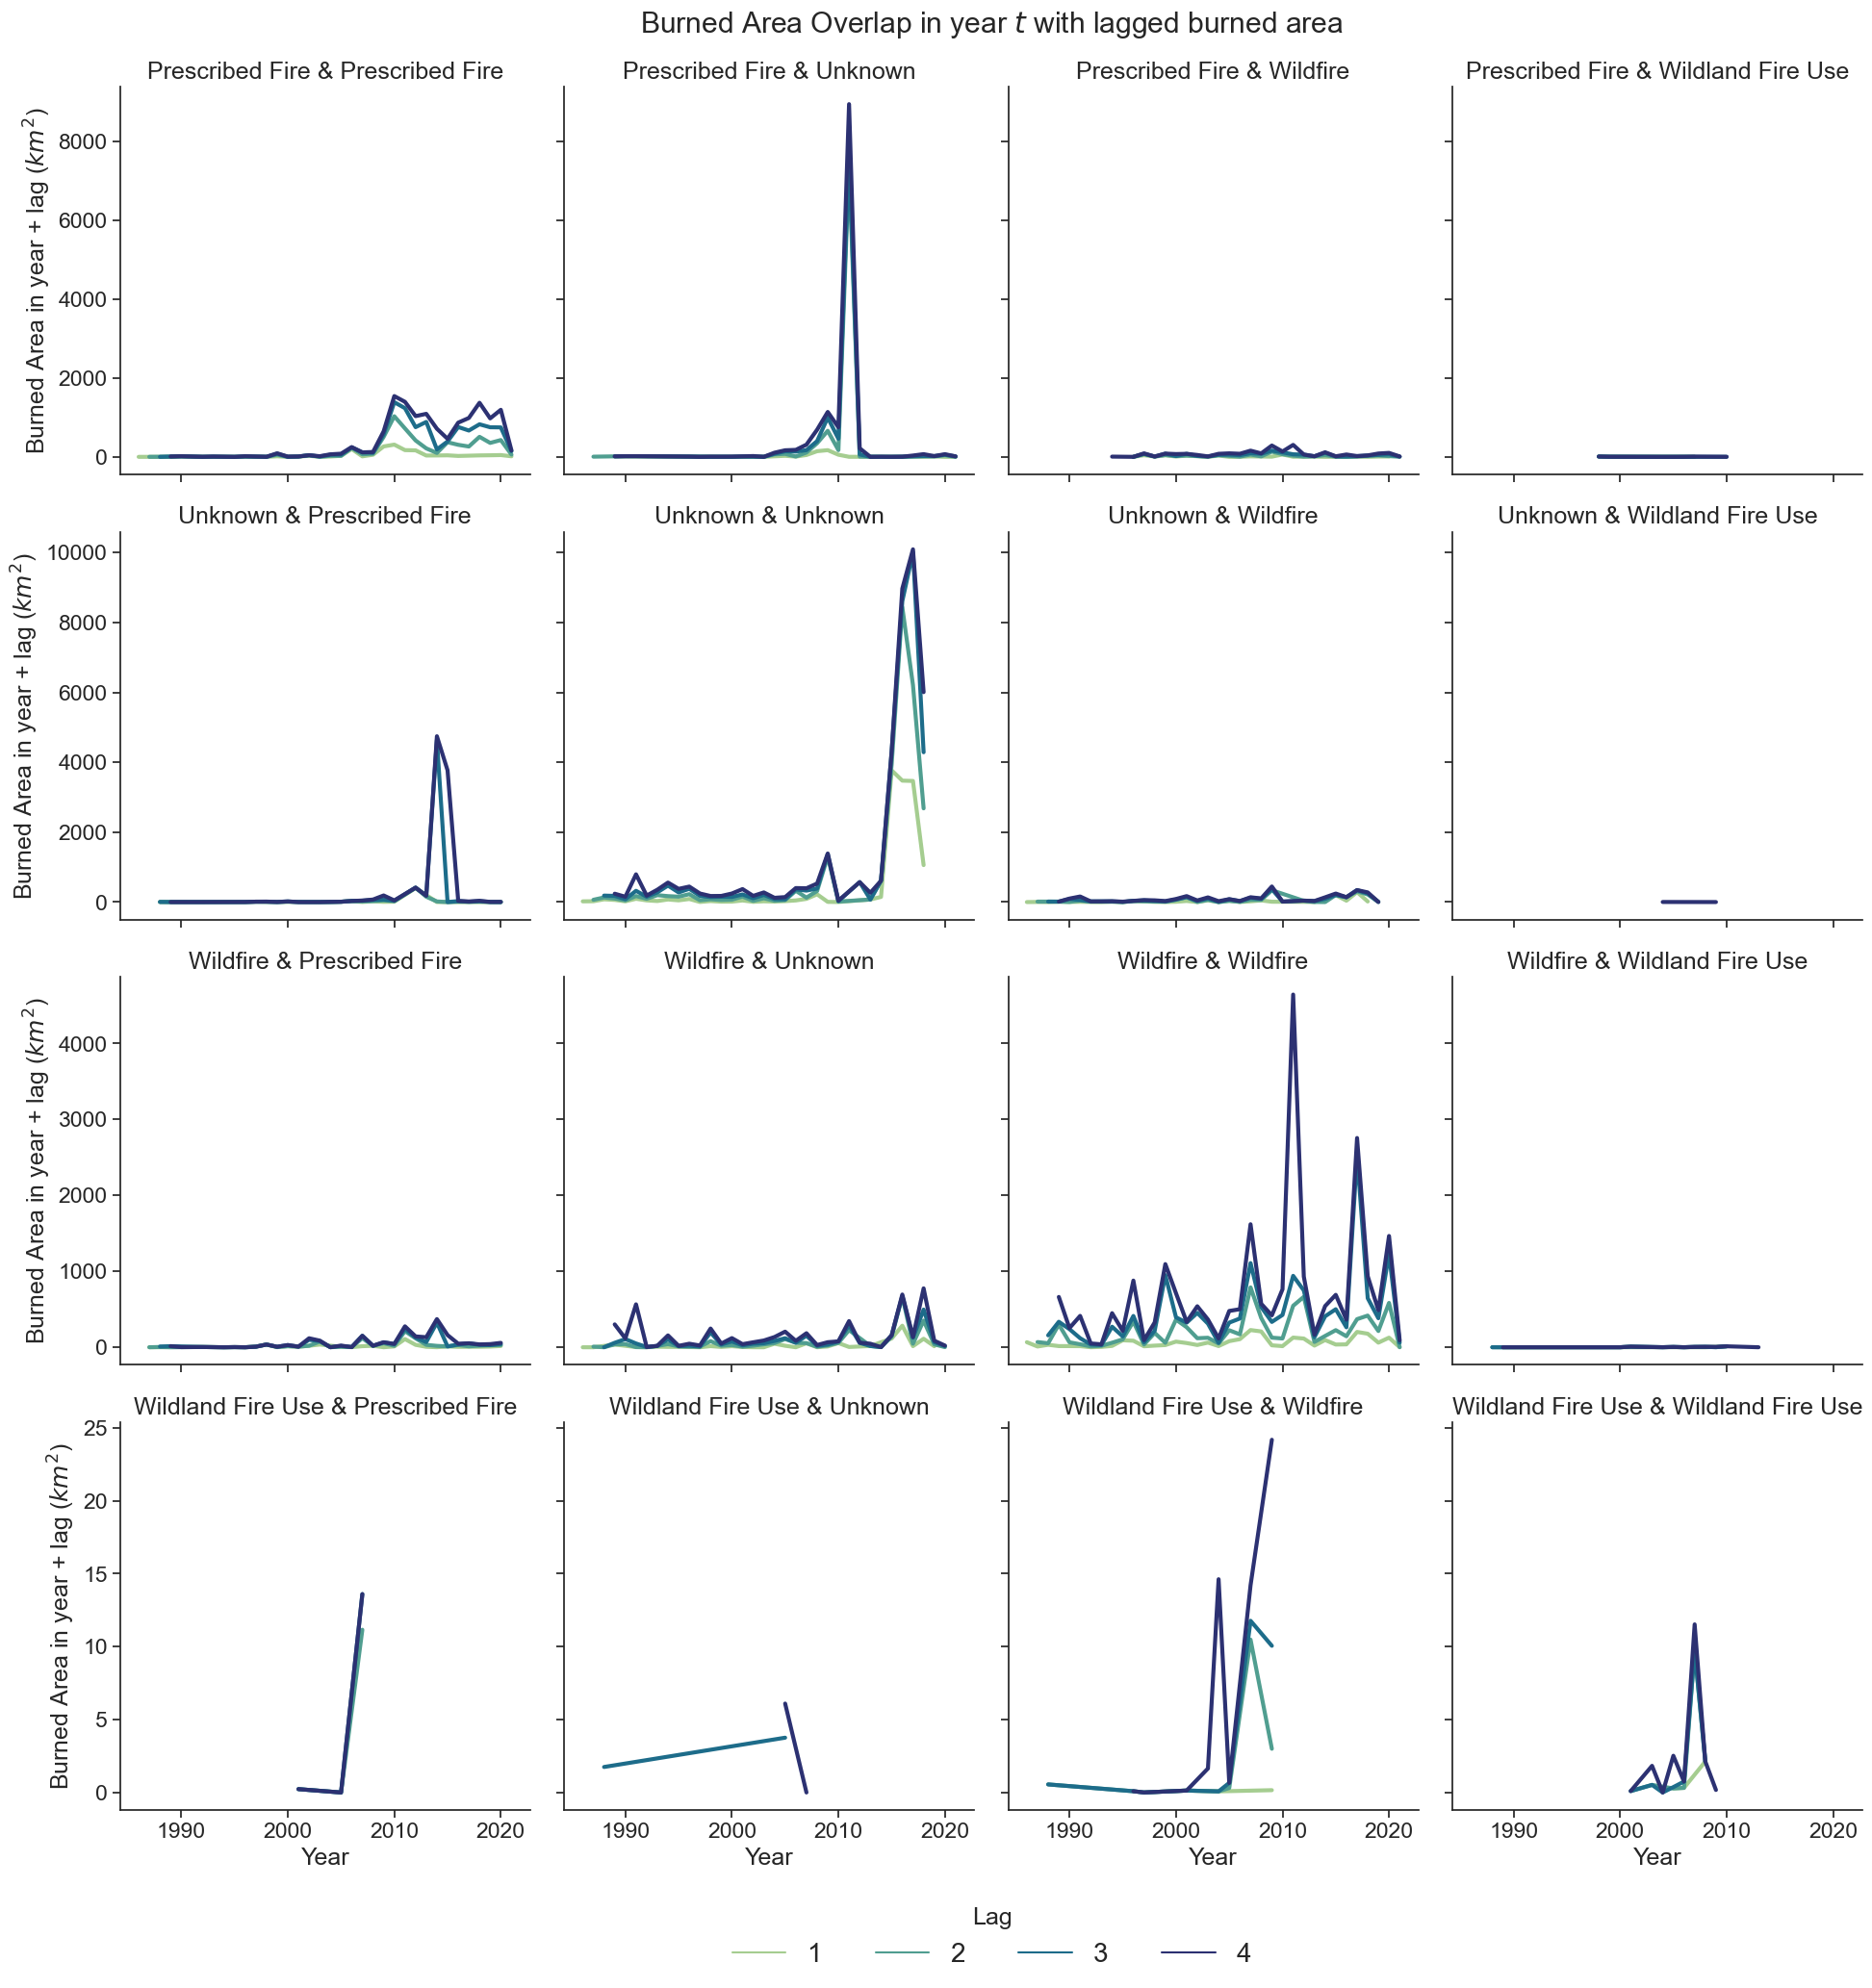

In [306]:
import seaborn as sns

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style='ticks', rc=custom_params)
sns.set_context("notebook", font_scale=1.5)

g = sns.relplot(
    data = area_overlap_concat.reset_index(),
    x='year', y = 'area_overlap', 
    col = 'fire_type_2', row = 'fire_type_1',
    hue = 'lag', kind = 'line', palette = 'crest', 
    linewidth = '3', facet_kws={'sharey': 'row'}
)
(g.set_axis_labels("Year", "Burned Area in year + lag ($km^2$)")
 .set_titles("{row_name} & {col_name}")
 .tight_layout()
)

g._legend.set_title("Lag")
sns.move_legend(g, 'lower center', ncol=4, title='Lag', 
                bbox_to_anchor = (0.5, -0.05), fontsize=20)

g.fig.suptitle('Burned Area Overlap in year $t$ with lagged burned area')
g.fig.subplots_adjust(top=0.94)

In [221]:
(
    area_overlap_concat
    .set_index('year')
    
)

,fire_type_1,fire_type_2,area_overlap,lag
year,,,,
1986,Prescribed Fire,Prescribed Fire,0.202935,1
1986,Unknown,Unknown,20.390565,1
1986,Unknown,Wildfire,0.142524,1
1986,Wildfire,Unknown,0.201432,1
1986,Wildfire,Wildfire,66.986709,1
...,...,...,...,...
2021,Wildfire,Wildfire,60.412842,3
2021,Prescribed Fire,Prescribed Fire,162.970809,4
2021,Prescribed Fire,Unknown,11.944165,4


In [196]:
fire_2020 = mtbs_per_us[mtbs_per_us.date.dt.year == 2020]
fire_2019 = mtbs_per_us[mtbs_per_us.date.dt.year == 2019]

In [205]:
overlap = gpd.overlay(fire_2020, fire_2019, how='intersection')
overlap['area'] = overlap.area

/var/folders/_l/ss1_csv9279c905rclvs4f840000gn/T/ipykernel_42747/3801777518.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  overlap['area'] = overlap.area


In [209]:
overlap.groupby(['fire_type_1', 'fire_type_2']).area.sum().to_frame().reset_index()

,fire_type_1,fire_type_2,area
0,Prescribed Fire,Prescribed Fire,0.004352
1,Prescribed Fire,Unknown,0.000011
2,Prescribed Fire,Wildfire,0.000877
3,Unknown,Prescribed Fire,0.000006
4,Wildfire,Prescribed Fire,0.001663
5,Wildfire,Wildfire,0.012663


In [165]:
for k, df in mtbs_per_us.groupby('fire_type'):
    print(f"{k} Len: {(df.shape)} ")

Prescribed Fire Len: (7498, 7) 
Unknown Len: (6393, 7) 
Wildfire Len: (16020, 7) 
Wildland Fire Use Len: (214, 7) 


<AxesSubplot:xlabel='date'>

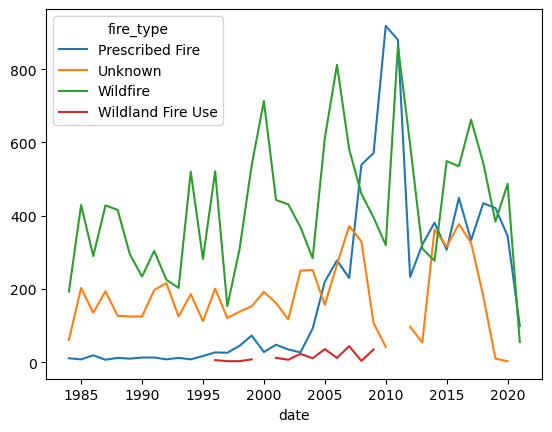

In [190]:
(mtbs_per_us
 .groupby(['fire_type', mtbs_per_us.date.dt.year])
 .fire_id
 .count()
 .to_frame()
 .reset_index()
 .pivot(index='date', columns='fire_type', values='fire_id')
 .plot()
)

In [144]:
years = mtbs_perimeters.date.dt.year.unique()
lags = np.arange(1, 6)


    a = 1

100%|█████████████████████████████████████████████████████████████| 152/152 [00:00<00:00, 173715.04it/s]
